# Corrected simulated data and extrapolation in time (Oct 13–14, 2026)

ZodiPy 1.1.5 is now installed (separate conda environment `zodipy`, see `zodipy_gen/`). Checking it against our data
turned up two errors in how the **original** simulated data were made, so this notebook has three parts:

* **A.** What is wrong with the original data, shown by reproducing it exactly.
* **B.** Corrected data (regenerated with ZodiPy): do the earlier conclusions still hold? Same tests, same recipe.
* **C.** **Extrapolation in time**: train on the whole 140-day mission and predict the same survey pattern up to
  1.5 years later.

Everything here uses the corrected data (`ENV["ZODI_DATA"] = "z115"`, results in `sweeps/results_z115/`). The original
files and every earlier result and notebook are unchanged.

### Summary
* **The original simulated data had two generation errors** (wrong observer origin; Earth's position extrapolated after
  mission day ~58). They put the data off by −6% to +4.6%, worst at the end of the mission. ZodiPy reproduces the
  original data to 3e-7 when it makes the same two mistakes.
* **On corrected data every earlier conclusion holds, and the numbers improve.** Season model, 30-day blocks: median
  0.024% (was 0.0325%). 80/20 chronological: p95 0.67% (was 1.04%), MSE 4× lower.
* **Extrapolation in time (trained on the 140-day mission):** the season model degrades to ~3% half a year later. The
  sin/cos λ⊕ inputs leave the training range for 60% of the year, and n·J acts as a clock.
* **Sun-frame inputs fix most of it.** Pointing measured from the Sun–Earth line instead of fixed x/y axes, no Jupiter,
  plus the season (**Sun frame + sin/cos λ⊕**, 9 inputs): worst case over the next 18 months **0.84%** (season model
  3.0%), back to 0.12% a year later. Inside the mission it is at least as accurate (MSE 0.87× the season model).
* **With a full year of training data** (simulated), Sun frame + sin/cos λ⊕ predicts the following 16 months at
  **0.10%** median, vs 0.024% on the training year. The season model with n·J gets 0.33%.


In [1]:
ENV["ZODI_DATA"] = "z115"          # corrected target; remove this line to get the original data back
include(joinpath(@__DIR__, "..", "zodi_setup.jl"))
for f in ("mb_train.jl", "extra_features.jl", "extra_splits.jl", "nb_verify_fns.jl", "summary_helpers.jl", "z115_helpers.jl")
    include(joinpath(@__DIR__, "..", "sweeps", f))
end
include(joinpath(@__DIR__, "..", "pipeline", "ZodiPipeline.jl")); using .ZodiPipeline


  Activating project at `c:\JuliaProjects\More_zodi`


target data: z115  (zodipy115_5um_boresight.h5);  results dir: sweeps\results_z115
description: Zodiacal light for SPHEREx pointing directions, regenerated with ZodiPy
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.32295323811551996, 1.1021098132583944)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.

## A. What is wrong with the original data
`zodipy_gen/reproduce_original.py` reproduces `spherex_zodipy_5um_boresight_interpolated.h5` to **3e-7** (rounding
level) with ZodiPy's Kelsall/DIRBE model at 5 μm when it makes two mistakes:

1. **Observer position.** SPHEREx's position relative to the solar-system **barycentre** was passed to ZodiPy, which
   expects a position relative to the **Sun**. The Sun is ~0.007 AU from the barycentre, so the observer sits in the
   wrong place → the original is **~2–3% too faint** everywhere.
2. **Earth extrapolated.** All exposures went through ZodiPy in **one batch in file order**. ZodiPy fits Earth's orbit
   with a spline between the *first and last times of the batch*. The file is not time-sorted: it starts at mission day
   6.2 and ends at day 57.8, so for every exposure outside that window Earth's position was **extrapolated**. Earth's
   position places the **circumsolar ring** and the **Earth-trailing blob**:

| mission day | 70 | 82 | 94 | 106 | 118 | 130 |
|---|---|---|---|---|---|---|
| error in "Earth" (AU) | 2e-4 | 2e-3 | 0.01 | 0.03 | 0.06 | 0.12 |
| error in Earth's longitude | 0.005° | 0.04° | 0.23° | 0.85° | 2.4° | 5.6° |

The corrected data (`zodipy_gen/generate.py`) use SPHEREx's heliocentric position and Earth's true position for every
exposure (de432s ephemeris; checked to agree with our vectors file to 1e-6 AU). (The logs below count days from the
file's `days_since_start`, which is mission day − 6.23.)


In [2]:
for f in ("reproduce_original.log", "generate.log")
    println("── zodipy_gen/$f"); foreach(println, readlines(joinpath(@__DIR__, "..", "zodipy_gen", f)))
end


── zodipy_gen/reproduce_original.log
﻿file order runs from day 0.00 to day 51.61 (mission -6.23..133.52)
reproduction of the original on 20000 exposures: median ratio 0.99999999, max |ratio - 1| 2.74e-07
── zodipy_gen/generate.log
﻿Earth: vectors file vs de432s: max |diff| 7.39e-07 AU
vectorised chunks vs one-by-one (40 exposures across the mission): max rel diff 1.31e-14
     2000/423607       0s  (eta    85s)
    42000/423607       9s  (eta    79s)
    82000/423607      17s  (eta    70s)
   122000/423607      25s  (eta    61s)
   162000/423607      33s  (eta    53s)
   202000/423607      41s  (eta    45s)
   242000/423607      49s  (eta    37s)
   282000/423607      58s  (eta    29s)
   322000/423607      66s  (eta    21s)
   362000/423607      74s  (eta    13s)
   402000/423607      83s  (eta     4s)
boresight done in 87s; new/old median 1.01939, range 0.9398..1.0457
all-sky map (786432 pixels) at exposure index 13169 (jd 2460790.2514) in 157s
DONE


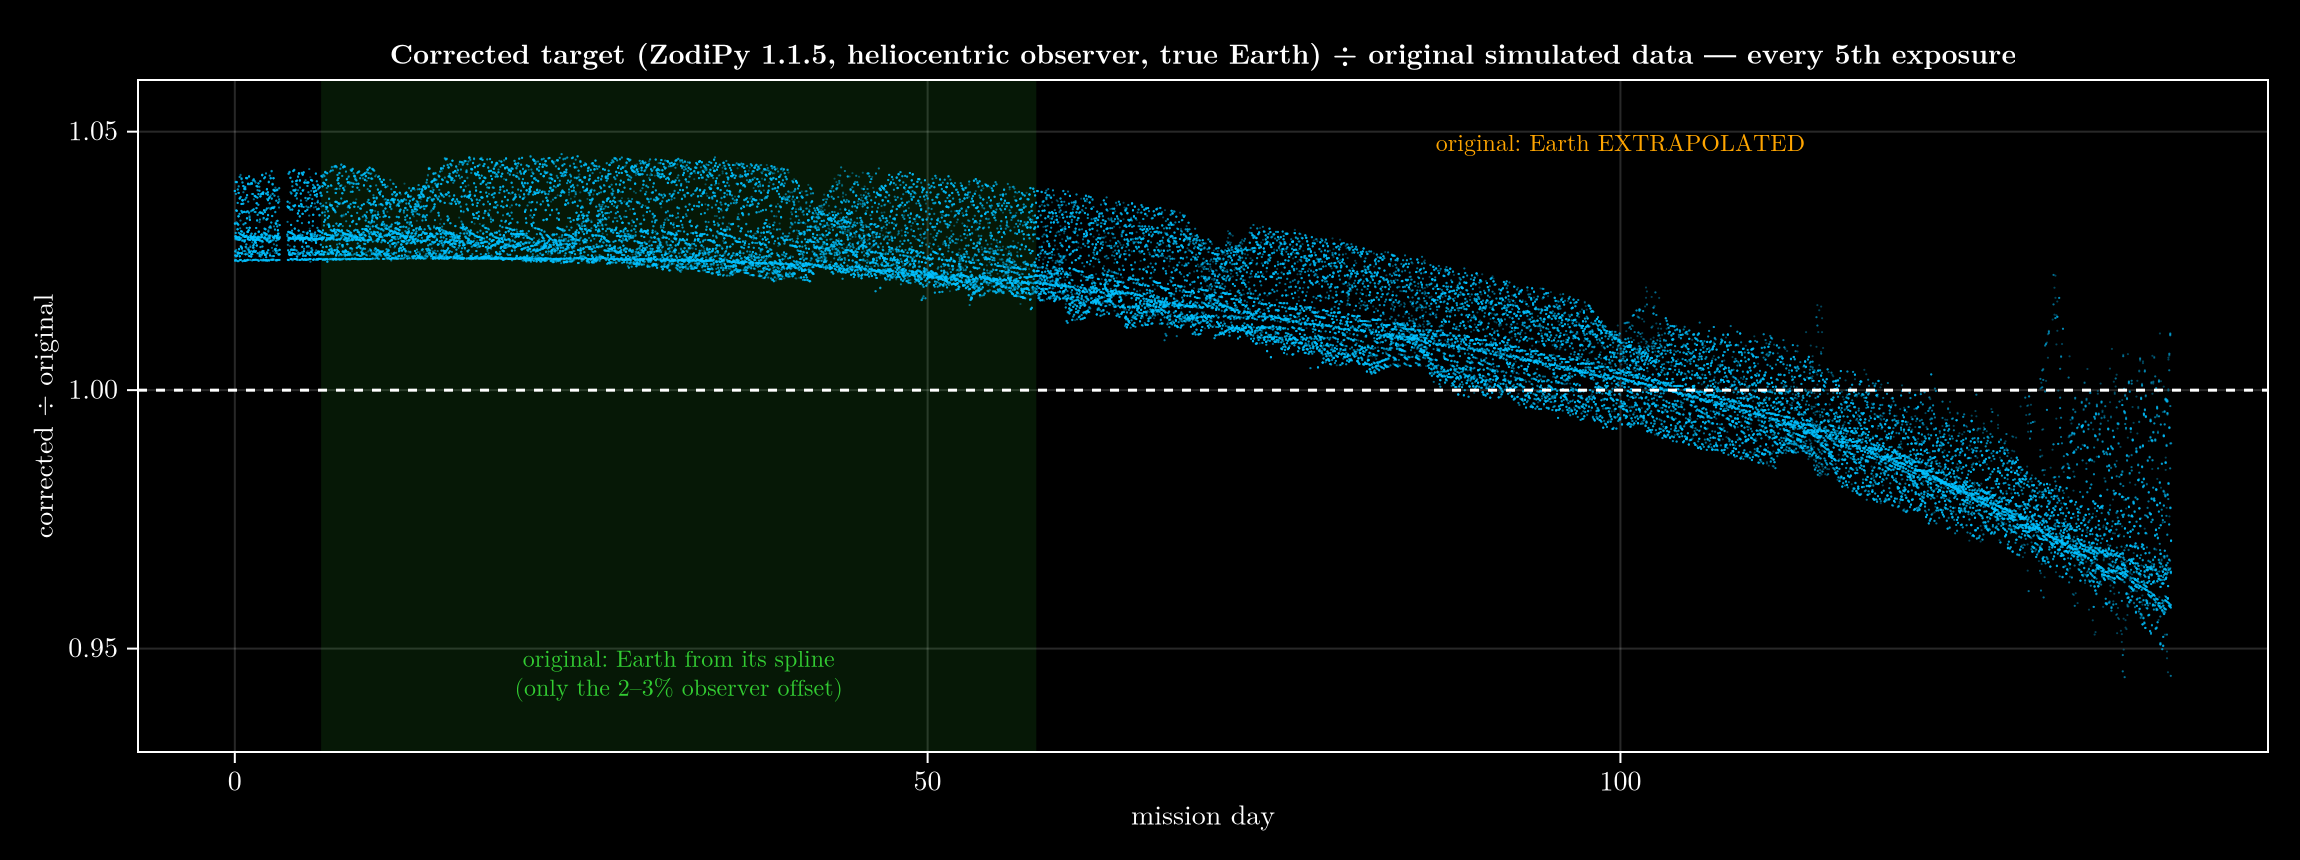

In [3]:
data_compare_fig()


## B. Corrected data: do the earlier conclusions hold?
Same splits, same recipe (64-64-32-16 MLP, batch 512, 100 epochs, one-cycle 1e-3), 5-seed ensembles. Each ensemble is
scored against the target it was trained on: original models vs the original data, new models vs the corrected data.
(Some older original-data runs only have 3 seeds; the `seeds` column shows original / corrected.)


In [4]:
ST = sanity_table()


Row,test,variant,seeds,original_median_pct,corrected_median_pct,original_p95_pct,corrected_p95_pct,original_mse,corrected_mse
,String,String,String,Float64,Float64,Float64,Float64,String,String
1,30-day blocks,n·* (no season),3 / 5,0.1668,0.1427,1.607,1.424,1.05e-05,8.67e-06
2,30-day blocks,season model,5 / 5,0.0325,0.024,0.137,0.113,2.02e-07,1.50e-07
3,30-day blocks,season − n·vS,5 / 5,0.0352,0.022,0.159,0.122,2.32e-07,1.67e-07
4,patch: ecliptic,season model,5 / 5,0.0538,0.0386,0.181,0.165,2.32e-07,1.97e-07
5,80/20 chronological,n·* (no season),5 / 5,0.5357,0.4946,4.873,3.866,9.40e-05,6.09e-05
6,80/20 chronological,season model,5 / 5,0.1284,0.1021,1.04,0.672,7.47e-06,1.76e-06
7,80/20 chronological,season − n·vS,5 / 5,0.1025,0.1272,1.255,0.688,1.23e-05,3.37e-06


The 80/20 chronological test holds out the last 20% of the mission, which is exactly where the original data were most
distorted (Earth extrapolated by up to 0.12 AU):


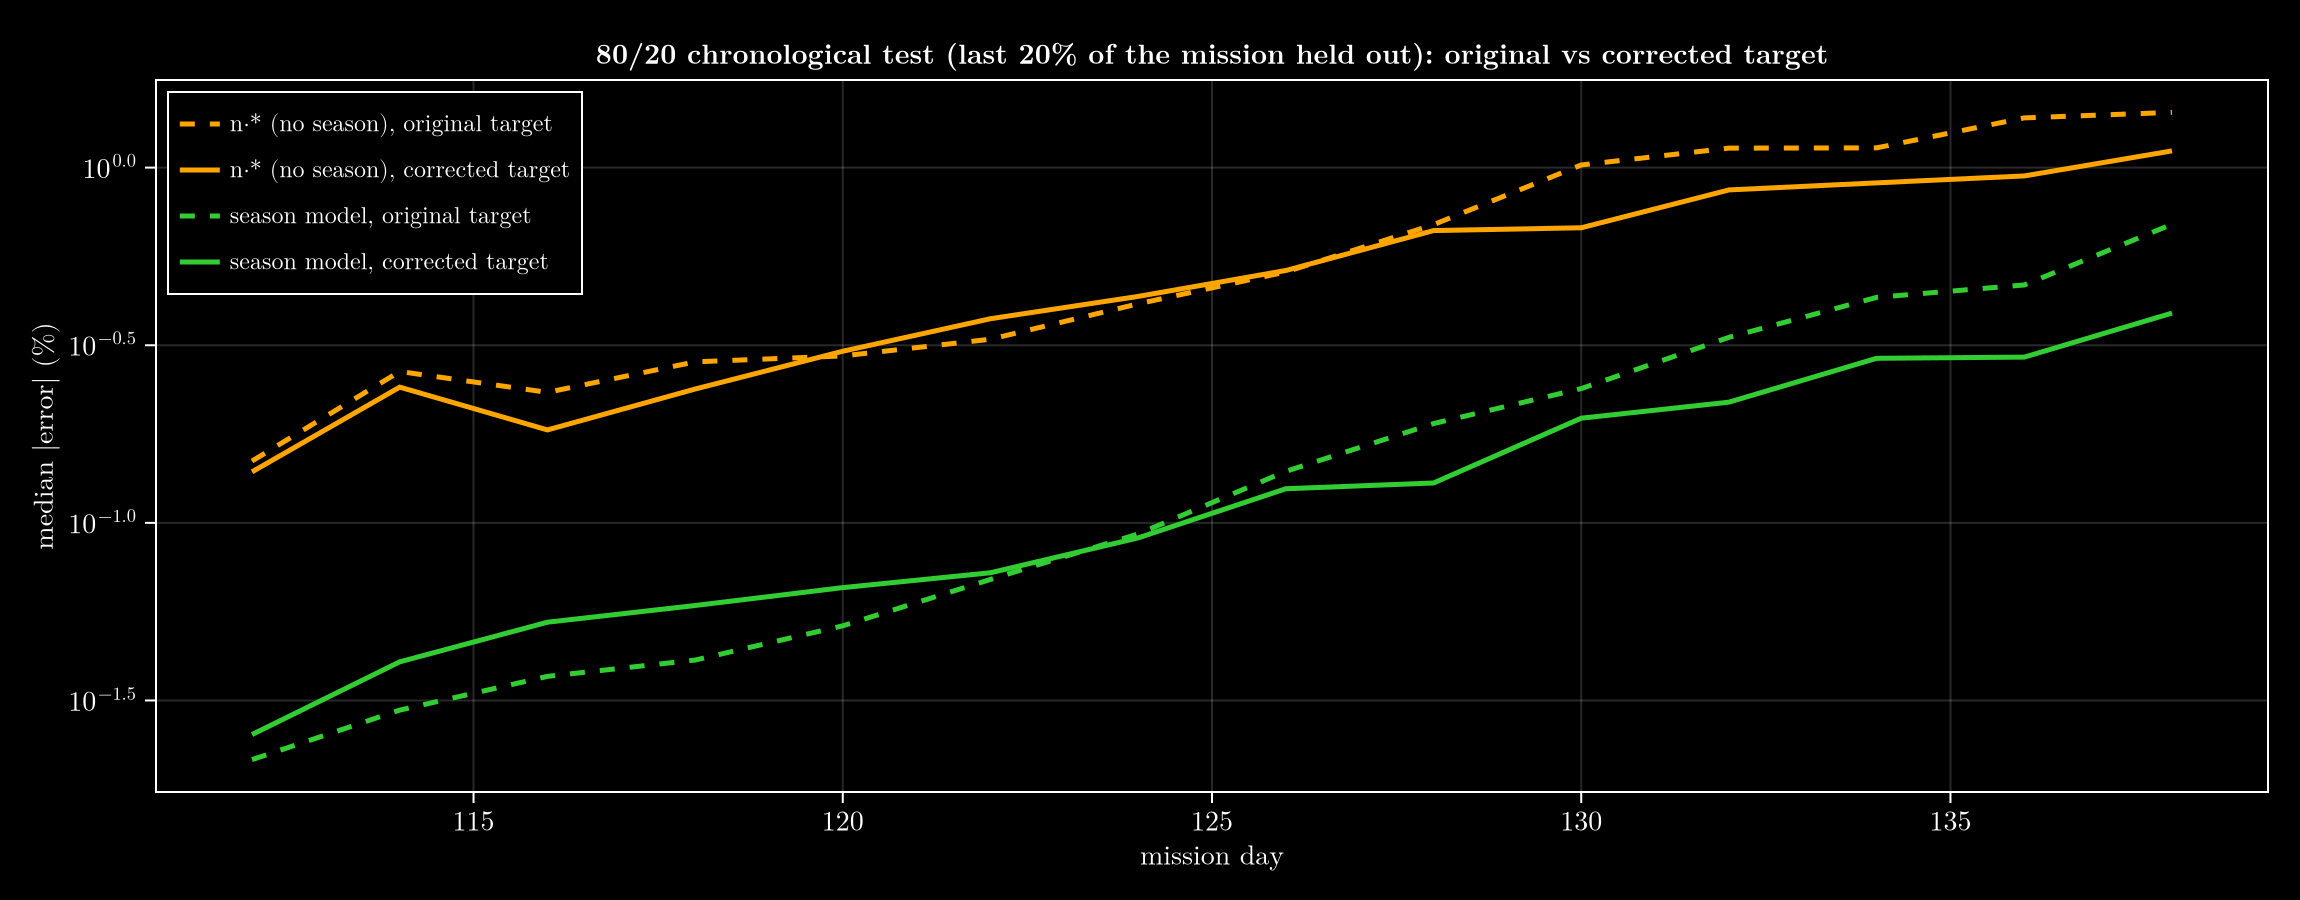

In [5]:
chrono_fig(arms=("base", "season"))


## C. Extrapolation in time
**Set-up.** Models are trained on the whole mission except a random 10% (`random 90/10`). The test set is synthetic:
6,000 mission exposures moved forward by Δ = 30, 60, …, 540 days. SPHEREx's survey is Sun-synchronous, so "the same
survey later" = pointing and SPHEREx's Earth-relative orbit **rotated about the ecliptic pole by how far Earth has moved
around the Sun**. Latitudes and Sun angles are kept (elongation changes ≤ 0.007°). Earth, Jupiter and velocities come from
the ephemeris; the truth comes from ZodiPy (`zodipy_gen/generate_future.py`). Features come from the real-data
pipeline. Check: on in-mission rows the pipeline reproduces the training predictions exactly:


In [6]:
println("pipeline vs stored predictions, season r90 ensemble: max relative difference = ", pipeline_selfcheck("season"))


pipeline vs stored predictions, season r90 ensemble: max relative difference = 0.0


Which inputs go outside what the network saw in training? (% of future exposures outside the 0.1–99.9% training range.)
The mission covers only ~38% of Earth's orbit, so **sin/cos λ⊕ (the season inputs) leave the training range** for most of
the year.


In [7]:
feature_range_table("season")


Row,feature,train_range,future_range,future_outside_pct
,String,String,String,Float64
1,n·S,-0.084 … 0.613,-0.085 … 0.635,0.1
2,n·z,-1.000 … 1.000,-1.000 … 1.000,0.2
3,n·E,-0.084 … 0.612,-0.085 … 0.635,0.1
4,n·vS,-0.997 … 1.000,-1.000 … 1.000,0.3
5,n·vE,-0.996 … 1.000,-1.000 … 1.000,0.3
6,n·J,-5.131 … 4.835,-5.309 … 5.322,3.6
7,n·x,-0.998 … 0.998,-1.000 … 1.000,0.1
8,n·y,-0.993 … 0.978,-1.000 … 1.000,1.0
9,sinλE,-1.000 … -0.205,-1.000 … 1.000,59.5


In [8]:
FT = future_table()


Row,shift,n·* (no season) (5) median %,season model (5) median %,season − n·vS (5) median %,season − n·J (5) median %,Sun frame (5) median %,Sun frame + sin/cos λ⊕ (5) median %,"Sun frame + cloud (n·ĉ, Zc, Rc) (5) median %","Sun frame + cloud (n·ĉ, Zc) (5) median %"
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,in-mission (held-out 10%),0.0522,0.015,0.0136,0.0146,1.4196,0.0148,0.0142,0.0256
2,+30 d,0.0833,0.0223,0.0191,0.0206,2.1051,0.0191,0.0172,0.0446
3,+60 d,0.1902,0.0495,0.0382,0.0436,3.7137,0.0349,0.0303,0.1518
4,+90 d,0.7899,0.206,0.1767,0.2805,5.1131,0.0987,0.0685,4.4259
5,+120 d,3.9957,0.8889,0.9926,1.3929,6.4971,0.3049,0.2321,9.0777
6,+150 d,14.5819,2.089,2.2944,2.9122,8.4361,0.5706,0.4707,10.0779
7,+180 d,20.5295,2.6858,2.8531,3.429,10.6398,0.7301,0.5175,10.0979
8,+210 d,21.0161,2.3644,2.6819,2.5897,11.3779,0.5028,0.5298,8.1951
9,+240 d,25.2298,1.919,2.4384,1.072,10.1924,0.3084,0.4463,3.7242


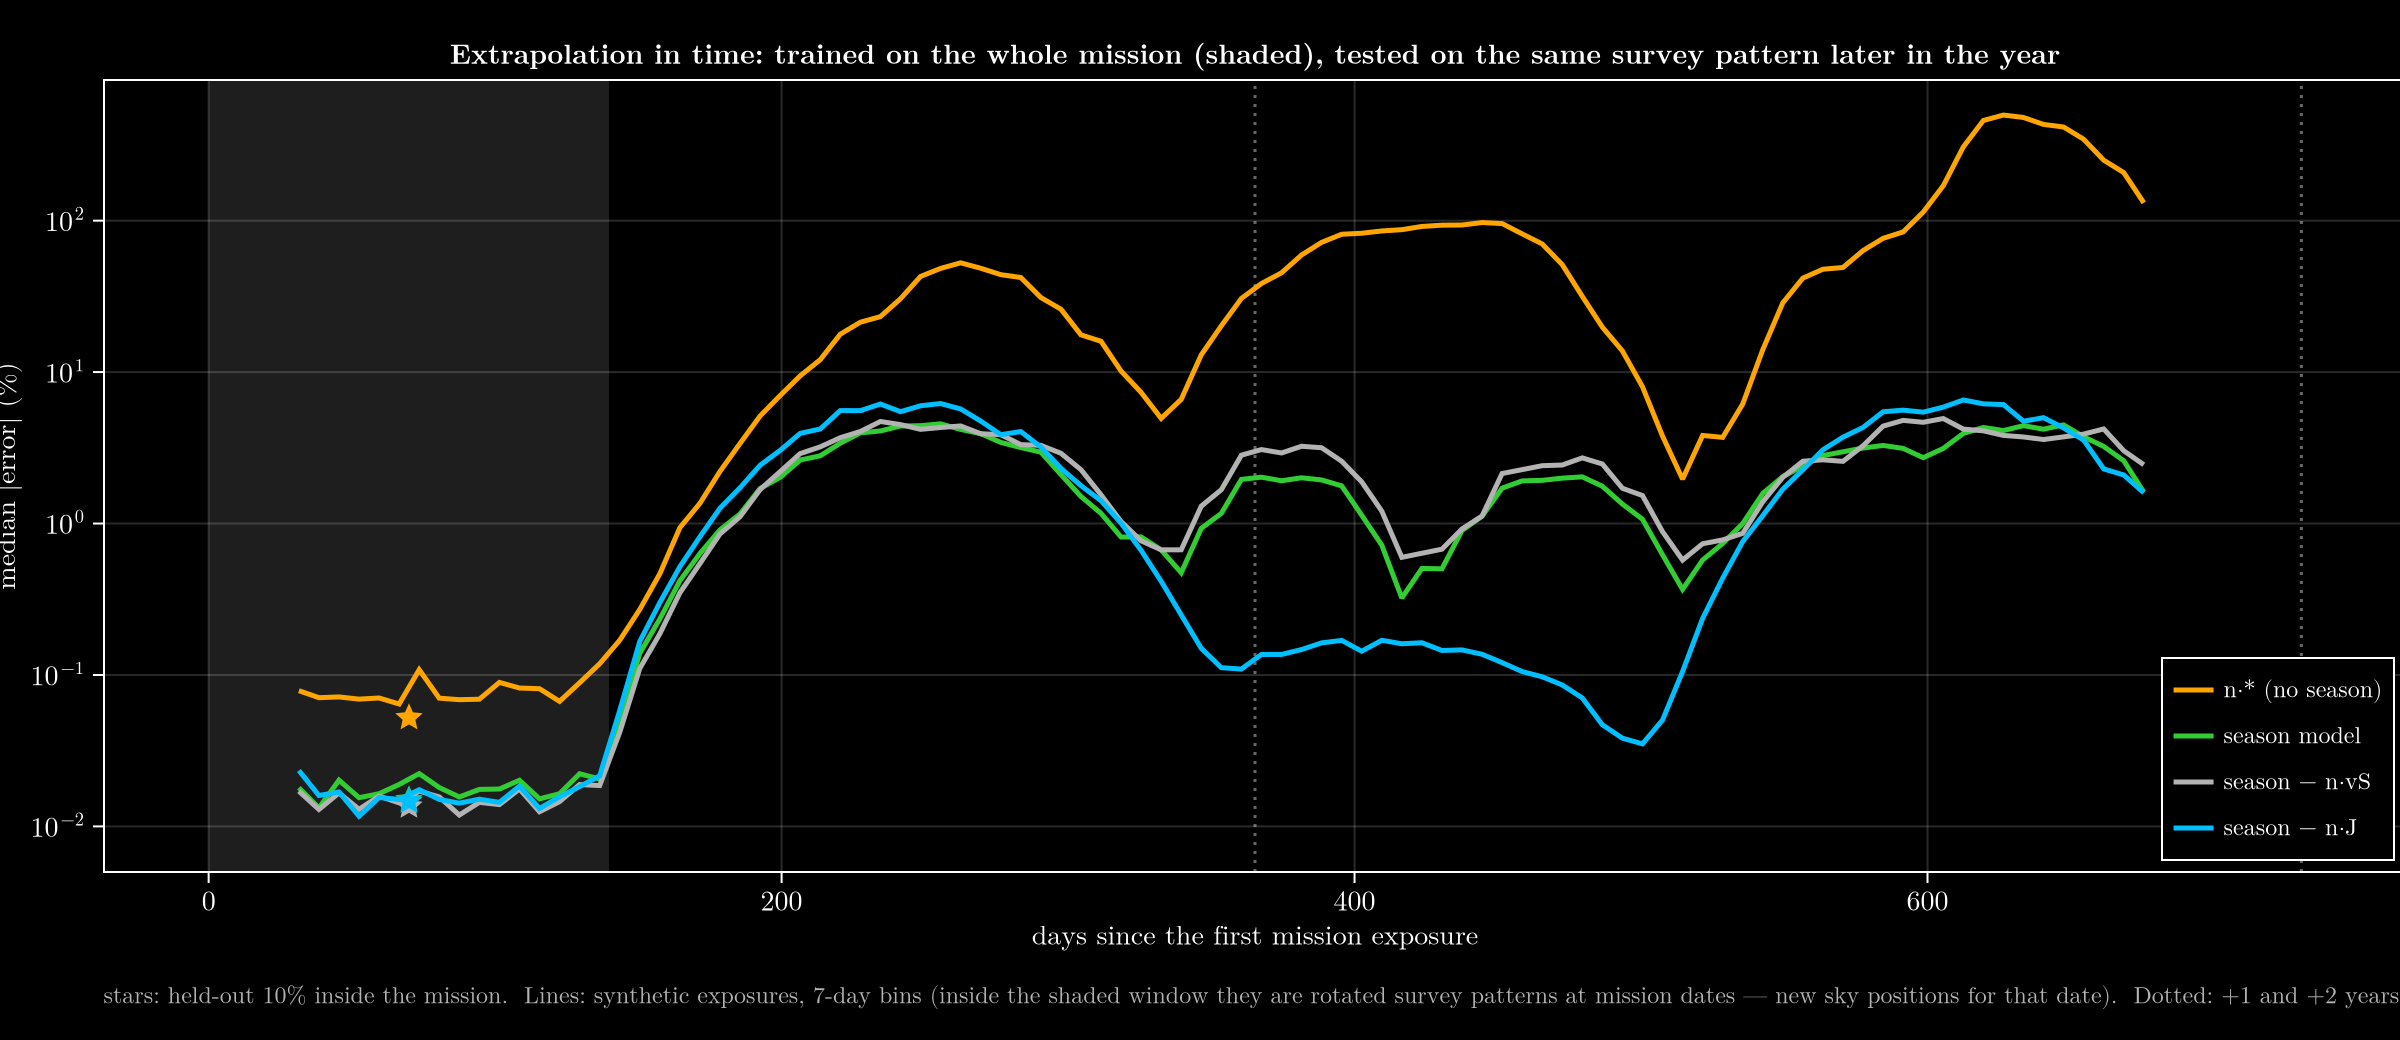

In [9]:
future_fig()


## D. Sun-frame inputs (round 11)
The look-direction inputs n·x, n·y (and n·J) are tied to fixed directions in space, and sin/cos λ⊕ only covers ~38% of
the year in the mission. Zodi brightness mostly depends on the geometry **relative to the Sun**, which turns with Earth.
New inputs (`sweeps/extra_features.jl`, also in the pipeline):

* **n·x⊕, n·y⊕**: the pointing in a frame rotated by Earth's longitude (x⊕ = Sun→Earth, y⊕ = direction of travel).
* **n·ĉ**: pointing · the smooth cloud's symmetry-plane normal (Kelsall: inclination 2.03°, node 77.66°).
* **Zc, Rc**: SPHEREx's height above the cloud's symmetry plane and its distance from the cloud centre.

| variant | inputs |
|---|---|
| Sun frame | n·S n·z n·E n·vS n·vE n·x⊕ n·y⊕ |
| + sin/cos λ⊕ | … + sinλ⊕ cosλ⊕ |
| + cloud (n·ĉ, Zc, Rc) | … + n·ĉ Zc Rc |
| + cloud (n·ĉ, Zc) | … + n·ĉ Zc |

None of these uses Jupiter or the fixed x/y axes. Ranges: n·x⊕, n·y⊕, n·ĉ stay inside the mission's range for the future
set (< 0.3% outside); Zc leaves it for 20% of the future exposures, Rc for 49% (the mission never got near perihelion).


In [10]:
feature_range_table("suncloud")


Row,feature,train_range,future_range,future_outside_pct
,String,String,String,Float64
1,n·S,-0.084 … 0.613,-0.085 … 0.635,0.1
2,n·z,-1.000 … 1.000,-1.000 … 1.000,0.2
3,n·E,-0.084 … 0.612,-0.085 … 0.635,0.1
4,n·vS,-0.997 … 1.000,-1.000 … 1.000,0.3
5,n·vE,-0.996 … 1.000,-1.000 … 1.000,0.3
6,n·J,-5.131 … 4.835,-5.309 … 5.322,3.6
7,n·x,-0.998 … 0.998,-1.000 … 1.000,0.1
8,n·y,-0.993 … 0.978,-1.000 … 1.000,1.0
9,sinλE,-1.000 … -0.205,-1.000 … 1.000,59.5


In-mission accuracy first (30-day blocks), compared with the season model:


In [11]:
interp_table()


Row,variant,features,seeds,median_err_pct,p95_err_pct,mse,vs_season
,String,Int64,Int64,Float64,Float64,String,Float64
1,n·* (no season),8,5,0.1427,1.424,8.67e-06,57.905
2,season model,10,5,0.024,0.113,1.50e-07,1.0
3,season − n·vS,9,5,0.022,0.122,1.67e-07,1.114
4,Sun frame,7,5,1.904,6.889,2.51e-04,1677.82
5,Sun frame + sin/cos λ⊕,9,5,0.0263,0.102,1.31e-07,0.873
6,"Sun frame + cloud (n·ĉ, Zc, Rc)",10,5,0.0216,0.101,1.24e-07,0.831
7,"Sun frame + cloud (n·ĉ, Zc)",9,5,0.1028,0.321,8.68e-07,5.796


In [12]:
FT11 = future_table()


Row,shift,n·* (no season) (5) median %,season model (5) median %,season − n·vS (5) median %,season − n·J (5) median %,Sun frame (5) median %,Sun frame + sin/cos λ⊕ (5) median %,"Sun frame + cloud (n·ĉ, Zc, Rc) (5) median %","Sun frame + cloud (n·ĉ, Zc) (5) median %"
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,in-mission (held-out 10%),0.0522,0.015,0.0136,0.0146,1.4196,0.0148,0.0142,0.0256
2,+30 d,0.0833,0.0223,0.0191,0.0206,2.1051,0.0191,0.0172,0.0446
3,+60 d,0.1902,0.0495,0.0382,0.0436,3.7137,0.0349,0.0303,0.1518
4,+90 d,0.7899,0.206,0.1767,0.2805,5.1131,0.0987,0.0685,4.4259
5,+120 d,3.9957,0.8889,0.9926,1.3929,6.4971,0.3049,0.2321,9.0777
6,+150 d,14.5819,2.089,2.2944,2.9122,8.4361,0.5706,0.4707,10.0779
7,+180 d,20.5295,2.6858,2.8531,3.429,10.6398,0.7301,0.5175,10.0979
8,+210 d,21.0161,2.3644,2.6819,2.5897,11.3779,0.5028,0.5298,8.1951
9,+240 d,25.2298,1.919,2.4384,1.072,10.1924,0.3084,0.4463,3.7242


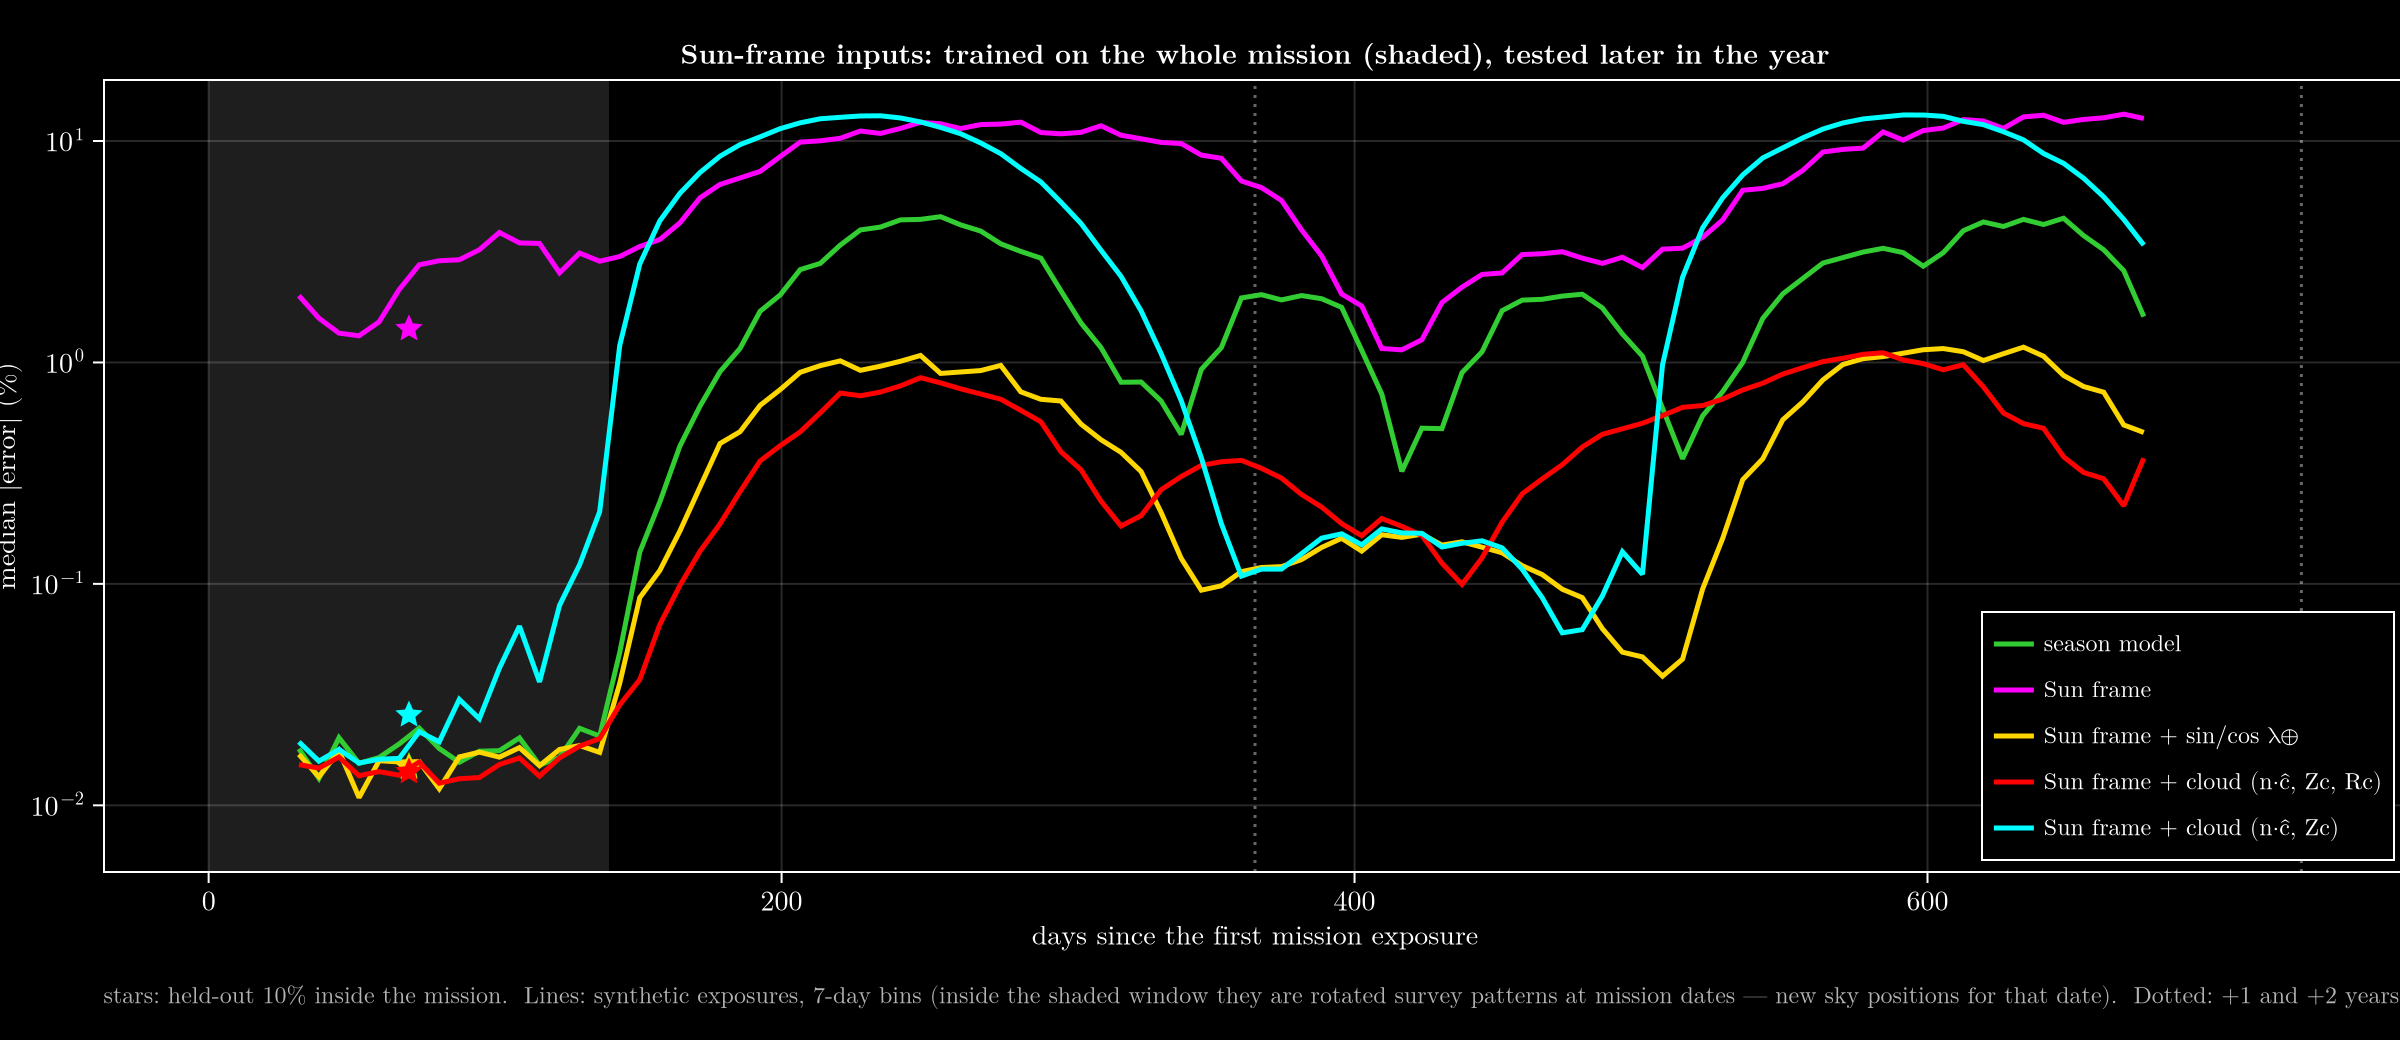

In [13]:
future_fig(vcat([("season", "season model")], ARMS11L); title="Sun-frame inputs: trained on the whole mission (shaded), tested later in the year")


## E. Train on a full simulated year, test on the next (round 12)
Can the emulator work all year round if the training data cover a full year? `zodipy_gen/generate_year.py` builds a
~2.3-year survey: the real mission (corrected target) plus the survey moved forward by 140, 280, 420, 560 and 700 days,
rotated with Earth's orbit (100,000 random exposures per copy, 600,000 in all). Training: the first 365 days
(~261,000 exposures). Test: everything after (days 365–840). The second year repeats the season, but Jupiter has moved
~30° and the Sun–barycentre offset has changed.


In [14]:
Y2T = year2_table()


Row,variant,features,seeds,year1_fit,year2_all,days 365–456,days 456–548,days 548–639,days 639–730,days 730–840
,String,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,n·* (no season),8,5,0.1015,2.4691,2.1479,2.6043,2.8678,0.9641,5.3824
2,season model,10,5,0.0231,0.3305,0.3632,0.7009,1.0041,0.1474,0.3689
3,season − n·J,9,5,0.023,0.1054,0.1393,0.0477,0.1334,0.0611,0.2613
4,Sun frame,7,5,3.5219,3.303,2.6786,5.1787,2.5126,5.5702,2.129
5,Sun frame + sin/cos λ⊕,9,5,0.0239,0.0996,0.1336,0.0418,0.1201,0.0645,0.2461
6,"Sun frame + cloud (n·ĉ, Zc, Rc)",10,5,0.0239,0.3837,0.138,0.5525,0.4215,0.4414,0.3138
7,"Sun frame + cloud (n·ĉ, Zc)",9,5,0.2014,0.3887,0.3428,0.3438,0.4049,0.3165,0.5194


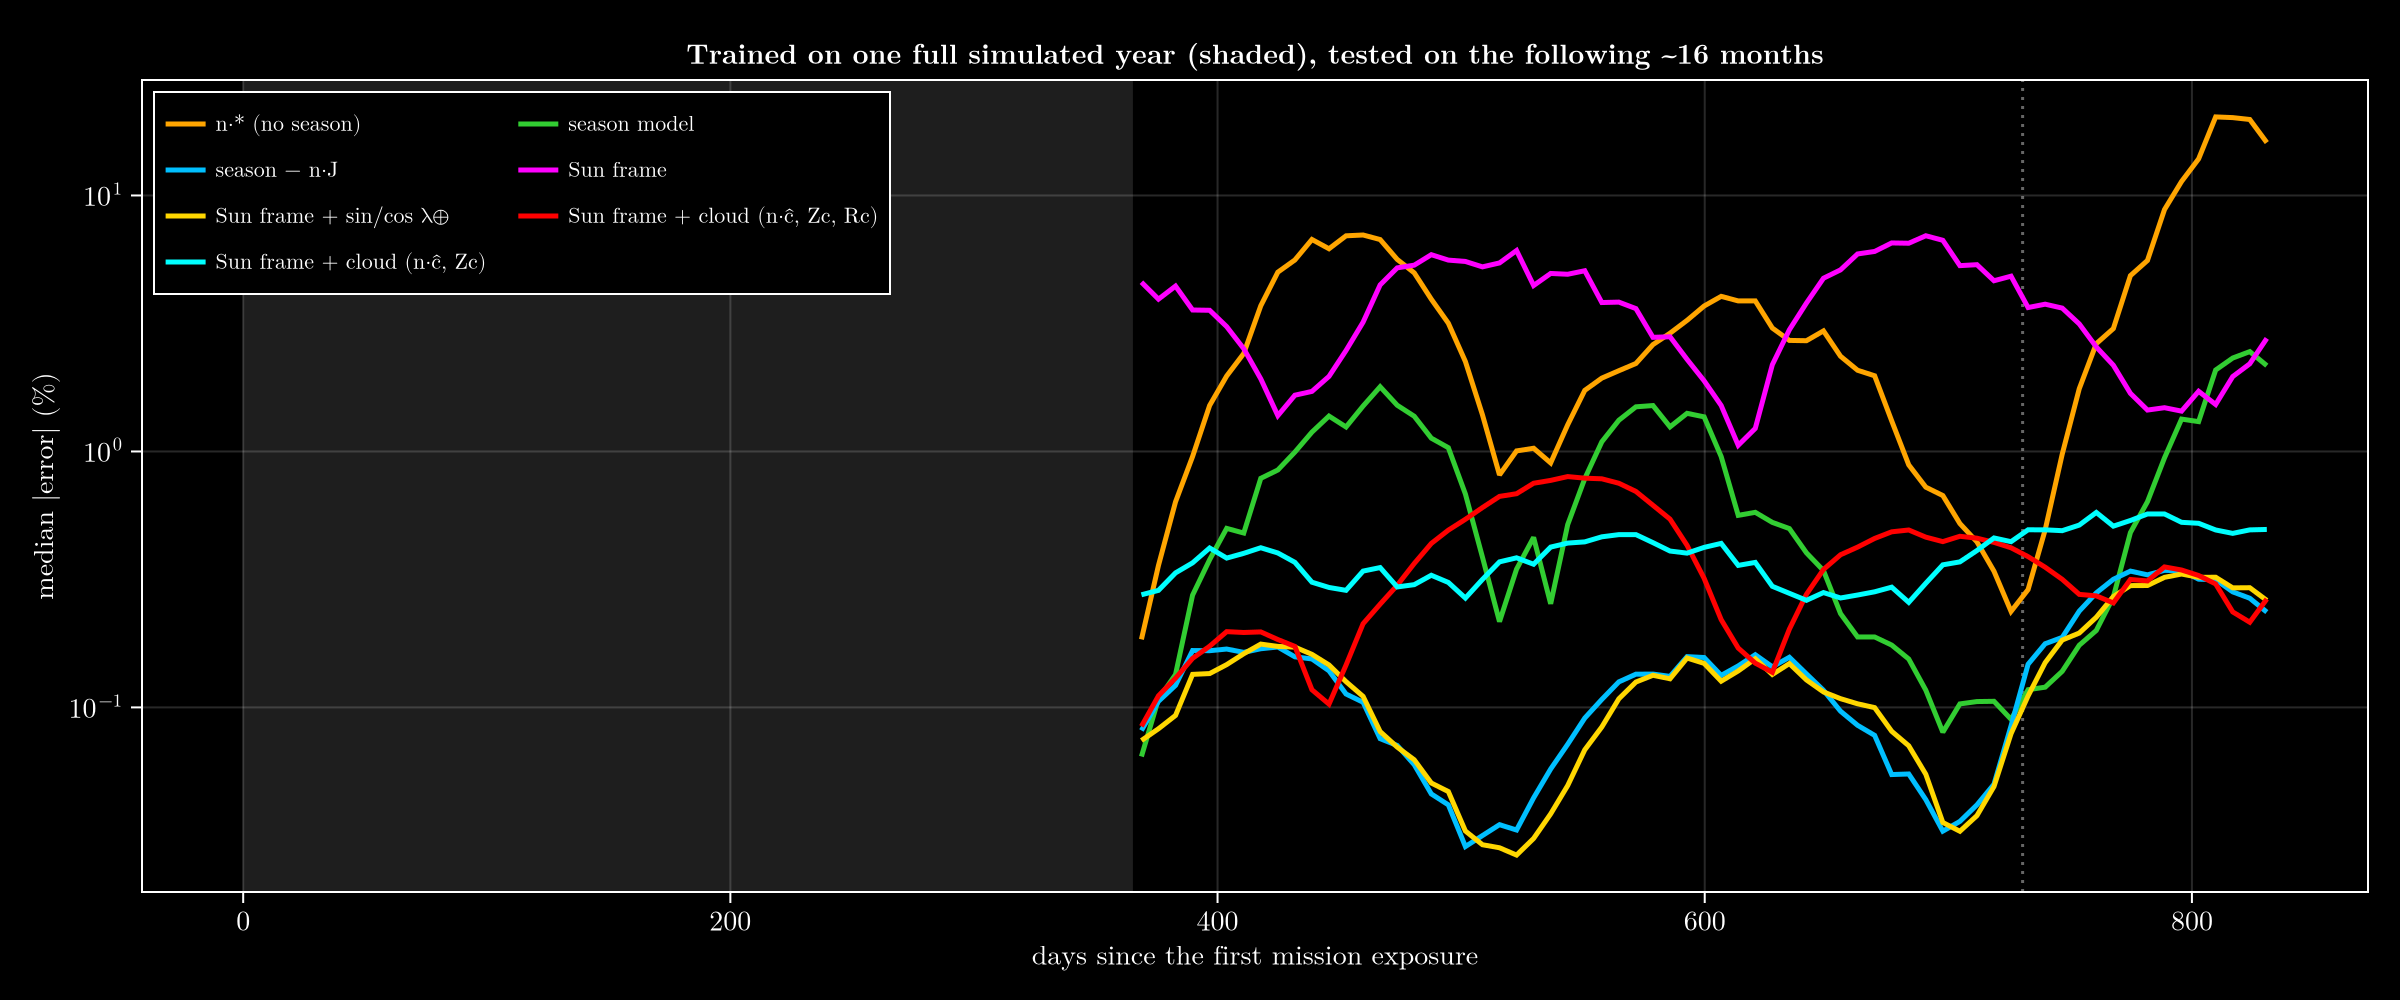

In [15]:
year2_fig()


## Conclusions
1. **Tell the mentor about the data errors** (`zodipy_gen/reproduce_original.py`, section A). The fixes are simple: pass a
   heliocentric observer position, and sort exposures by time (or evaluate in time-ordered chunks) before a ZodiPy batch
   call. Any other data made with the same script likely has the same issue.
2. **Use the corrected data from now on** (`ENV["ZODI_DATA"] = "z115"`). Every comparison in this notebook improved on it.
   Earlier notebooks stay valid as relative comparisons, but their absolute late-mission numbers include the data error.
3. **New recommended inputs: Sun frame + sin/cos λ⊕** (n·S n·z n·E n·vS n·vE n·x⊕ n·y⊕ sinλ⊕ cosλ⊕: no Jupiter, no fixed
   x/y axes). It was the best or tied for best in all three regimes:

   | regime | season model | Sun frame + sin/cos λ⊕ |
   |---|---|---|
   | inside the mission (30-day blocks), MSE | 1× | 0.87× |
   | trained on the mission → next 18 months, worst 30-day shift | 3.0% | 0.84% |
   | trained on a full year → the next 16 months, median | 0.33% | 0.10% |

4. **The cloud-geometry inputs (n·ĉ, Zc, Rc)** extrapolate about as well from the mission alone (worst 0.76%). With a full
   year of data they fall behind sin/cos λ⊕ (0.38% vs 0.10%). Rc is essential to them: without it the error reaches 10%
   mid-year, because Earth's distance from the Sun goes outside the mission's range. Sin/cos λ⊕ is simpler and better
   once a year of data exists.
5. **For real data:** the model can be trusted about 3 months beyond the observed season (≤ 0.1% at +90 days, 0.3% at +120).
   Year-round accuracy needs year-round training data; with one year, the next year is at ~0.1%. The remaining year-2
   error (4× the training-year error) probably comes from slow changes the inputs don't see (the Sun's offset from the
   barycentre, Earth's orbit vs calendar); a candidate for later.
6. **Next steps:** emulator v2 with the Sun frame + sin/cos λ⊕ inputs, trained on the corrected data; rerun the remaining
   earlier tests (block lengths, patches, all-sky) with those inputs; multi-wavelength (SPHEREx spans 0.75–5 μm).
